# dupont tutorial: how the PoET + MURaM mask was built

A line enters the mask when it is found in both the PoET spectrum (the Sun observed with ESPRESSO, 89 S1D of 15 May
2026) and the disc-integrated MURaM quiet Sun, and passes every test. Each threshold is a column `flag_*` of the line
table (True: the line fails it) and the mask is the lines with no flag. The construction and the line table cover the
whole range, 3800-7890 Å; the tests that recompute spectra (steps 2, 4 and 6) run on `TEST_RANGE` (5000-5600 Å). Each step is followed by its test.

| step | what | threshold | column |
|---|---|---|---|
| 1 | PoET: mean of the 89 S1D | | |
| 2 | flattening (SNT) | radius 50-200, blue / red fits joined at 4200 Å | |
| 3 | frame: CCF with the ESPRESSO mask at 0 | | |
| 4 | MURaM: disc (60 rings), air, flattened, same frame, R = 190 000 | | |
| 5 | telluric model: H₂O + O₂ fitted to PoET / MURaM | | |
| 6 | lines: minima, gaussian core, window edges from the derivatives | prominence 0.05, core 0.2, 3σ | `obs_*`, `syn_*` |
| 7 | pairs: one to one, global shift removed; window rule; shared window | 4 km$\,$s$^{-1}$; \|Δv\| > 2 km$\,$s$^{-1}$ | `dv`, `flag_dv` |
| 8 | telluric absorption in the window ± 1 km$\,$s$^{-1}$ | depth > 0.1 % | `flag_telluric` |
| 9 | line found in every exposure | prominence 0.025 | `n_s1d`, `flag_not_in_all_s1d` |
| 10 | VALD matching | | `vald_*`, `flag_no_vald` |
| 11 | weights: Bouchy et al. (2001) eq. 8, A0 = flattened flux, σ_D = 0, shared window | | `obs_weight`, `syn_weight` |
| 12 | ESPRESSO matching | 0.11 Å; minima within 0.05 Å | `in_espresso`, `flag_esp_far` |
| 13 | mask: no flag, PoET minima and weights | | |

The same steps are in `CAUP/making_mask_flags.ipynb` (whole range, more tests). `lm.extract_mask` (section 14) does
the general case, any number of spectra, with fewer flags.

The functions come from `dupont` (`CAUP/dupont/src/dupont`, imported as `lm`, plots as `lp`):

| file | used here |
|---|---|
| `spectra.py` | `stack_s1d`, `read_s1d`, `continuum_snt`, `flatten`, `FLATTEN`, `degrade_resolution`, `common_grid`, `load_spectrum`, `vacuum_to_air`, `doppler_shift` |
| `prepare.py` | `read_mu_spectra`, `disc_integrate`, `to_rest` |
| `ccf.py` | `ccf`, `ccf_params`, `photon_rv_error`, `RV_GRID` |
| `tellurics.py` | `fit_quality`, `telluric_depth` (the fit: `hitran_tau_grid`, `fit_tellurics_joint`) |
| `lines.py` | `detect_lines`, `load_vald`, `identify` |
| `pairing.py` | `pair_lines`, `shared_window`, `rv_weights`, `match_reference` |
| `flags.py` | `presence_in_windows`, `select`, `first_flag`, `summary` |
| `pipeline.py` | `load_reference_mask` |
| `extract.py` | `compare_ccfs`, `write_mask`, `extract_mask`, `ExtractConfig` |
| `plots.py` | `flag_scatter` |

In [1]:
import os, sys, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('src'))          # or: pip install -e .
import dupont as lm
from dupont import plots as lp


def data_dir(key):
    """Folder of `key`: environment variable DUPONT_<KEY>, otherwise SunSim's local paths if sunsim is installed."""
    if os.environ.get('DUPONT_' + key.upper()):
        return Path(os.environ['DUPONT_' + key.upper()]).expanduser()
    try:
        from sunsim import local_path
    except ImportError:
        raise FileNotFoundError('set the environment variable DUPONT_%s' % key.upper()) from None
    return local_path(key)


POET = data_dir('poet_data')                        # S1D_A/ and output/ of PoET
S1D_FILES = sorted(glob.glob(str(POET / 'S1D_A' / '*_S1D_A.fits')))            # 89 S1D of 15 May 2026 (SINGLEUHR)
ESPRESSO_FILE = lm.mask_path('ESPRESSO_SUN.csv')                                # ESPRESSO mask: wave, cont
VALD_FILE = POET / 'output' / 'SUN_LINELIST_VALD_2.csv'                         # VALD line list (air)
MURAM = data_dir('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'   # quiet Sun, mu grid
MURAM_DISC_FILE = POET / 'output' / 'SUN_SPECTRUM_MURAM_DISC_N60_R50.csv'       # step 4 on the whole range
TELL_FILE = POET / 'output' / 'mask_flags' / 'TELL_SPECTRUM_HITRAN_JOINT.csv'   # HITRAN joint fit (step 5)
TELL_FITS = POET / 'output' / 'mask_flags' / 'telluric_joint_fits.csv'
FULL_RANGE = (3800.0, 7890.0)                       # [Å] range of the mask
TEST_RANGE = (5000.0, 5600.0)                       # [Å] tests of steps 2, 4, 6 (they recompute spectra)
RESOLUTION = lm.ESPRESSO_RESOLUTION['SINGLEUHR']    # 190 000
TH = dict(prominence=0.05, core=0.2,                # 6: detection, core of the gaussian fit
          sg_window=9, sg_order=3, edge_sigma=3.0,  # 6: window edges (Savitzky-Golay derivatives, significance)
          max_dv_pair=4000.0, max_dv=2000.0,        # 7: [m/s] pairs kept; flag_dv above (and pairs of the global shift)
          telluric=0.001, telluric_dv=(-1000.0, 1000.0),   # 8: model depth; [m/s] window widened
          s1d_prominence=0.025,                     # 9: detection in one exposure
          blend_depth=0.5, blend_min_sep=0.01,      # 10: VALD blends (information, no flag)
          esp_tol=0.11, esp_max_dwave=0.05)         # 12: [Å] ESPRESSO match, flag_esp_far
FLAGS = ['flag_dv', 'flag_telluric', 'flag_not_in_all_s1d', 'flag_no_vald', 'flag_esp_far']
OUT = None                                          # folder for the line table and the mask (None: not saved)
C = lm.C_LIGHT
pd.options.display.float_format = '{:.3f}'.format
print('%d S1D files' % len(S1D_FILES))

89 S1D files


## 1. PoET: stack of the 89 S1D

`lm.stack_s1d` scales every S1D to the median flux of the first one and averages them; the error is propagated and
only the pixels good in every exposure are kept. **Test**: S/N per pixel of the stack and of one exposure (gain √89).

In [2]:
w_raw, f_raw, e_raw, s1d_info = lm.stack_s1d(S1D_FILES)
k = (w_raw > FULL_RANGE[0] - 20) & (w_raw < FULL_RANGE[1] + 20)               # 20 Å beyond: no SNT edge inside
w_raw, f_raw, e_raw = w_raw[k], f_raw[k], e_raw[k]
print('%d S1D (%s), flux scale factors %.3f-%.3f' % (len(S1D_FILES), s1d_info['mode'].iloc[0], s1d_info['scale'].min(),
                                                     s1d_info['scale'].max()))

89 S1D (SINGLEUHR), flux scale factors 0.990-1.061


## 2. Flattening

`lm.continuum_snt` (SNT, `lm.FLATTEN`): the upper envelope of the spectrum with an alpha shape of radius 50 (continuum)
to 200 (steep wings of the broad lines), the blue and red parts fitted separately (FWHM 0.1 and 0.5 Å) and joined at
4200 Å. **Test**: three radii on `TEST_RANGE` (same settings otherwise): flatness of the continuum (99th percentile of
every 10 Å), equivalent width of Mg b, number of lines.

,median |p99 - 1| [10^-3],EW Mg b [Å],lines (prominence 0.05)
20-70,0.213,4.916,848.000
50-200 (used),0.412,5.089,848.000
100-400,0.859,5.089,848.000


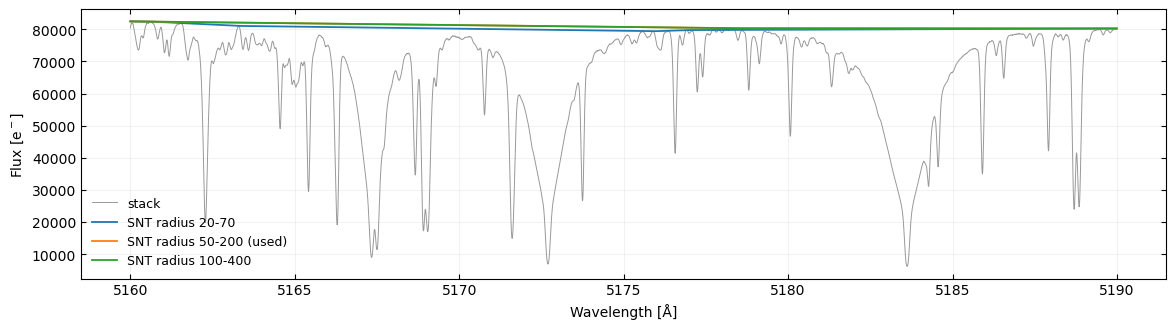

In [3]:
cont_stack = lm.continuum_snt(w_raw, f_raw, **lm.FLATTEN)
w_p, f_p, e_p = lm.flatten(w_raw, f_raw, e_raw, continuum=cont_stack)

q = (w_raw > TEST_RANGE[0] - 20) & (w_raw < TEST_RANGE[1] + 20)
radii = {'20-70': (20, 70), '50-200 (used)': (50, 200), '100-400': (100, 400)}
rows, conts = {}, {}
for name, (a, b) in radii.items():
    conts[name] = lm.continuum_snt(w_raw[q], f_raw[q], **dict(lm.FLATTEN, snt_config={'radius_min': a, 'radius_max': b}))
    y, w = f_raw[q] / conts[name], w_raw[q]
    p99 = [np.nanpercentile(y[(w >= x) & (w < x + 10)], 99) for x in np.arange(*TEST_RANGE, 10)]
    mgb = (w > 5164) & (w < 5187) & np.isfinite(y)
    rows[name] = {'median |p99 - 1| [10^-3]': 1e3 * np.median(np.abs(np.array(p99) - 1)), 'EW Mg b [Å]': np.trapezoid(1 - y[mgb], w[mgb]),
                  'lines (prominence 0.05)': len(lm.detect_lines(w, np.nan_to_num(y, nan=1.0), 0.05, center='pixel'))}
display(pd.DataFrame(rows).T)
fig, ax = plt.subplots(figsize=(14, 3.5))
z = (w_raw > 5160) & (w_raw < 5190)
ax.plot(w_raw[z], f_raw[z], color='0.6', lw=0.7, label='stack')
for name, c in conts.items():
    ax.plot(w_raw[z], c[z[q]], lw=1.3, label='SNT radius ' + name)
ax.set_xlabel('Wavelength [Å]'); ax.set_ylabel('Flux [e$^-$]'); ax.legend(frameon=False, fontsize=9); lp._style(ax)
plt.show()

## 3. Frame

The stack is shifted so that its CCF with the ESPRESSO mask (weights = contrast) is at 0: the frame of the mask. **Test**: RV of the shifted stack with the same mask.

In [4]:
esp_csv = pd.read_csv(ESPRESSO_FILE)
rv_stack = lm.ccf_params(lm.RV_GRID, lm.ccf(w_p, f_p, esp_csv['wave'].values, esp_csv['cont'].values))['rv']
w_p = lm.doppler_shift(w_p, -rv_stack)
print('RV of the stack: %.2f m/s removed' % rv_stack)
rv_after = lm.ccf_params(lm.RV_GRID, lm.ccf(w_p, f_p, esp_csv['wave'].values, esp_csv['cont'].values))['rv']
print('RV of the shifted stack: %.3f m/s' % rv_after)

RV of the stack: 147.37 m/s removed
RV of the shifted stack: -0.002 m/s


## 4. MURaM: disc-integrated quiet Sun

`lm.disc_integrate`: the µ grid on every cell of the disc (SunSim spectroscopic mode, 60 rings, solar rotation and
differential rotation), summed; then vacuum → air, flattened as PoET (step 2), and shifted into the ESPRESSO frame (step
3). The mask uses the same construction over the whole range (`MURAM_DISC_FILE`), convolved to R = 190 000 with
`lm.degrade_resolution`. **Tests**: the disc built here against that file; MURaM native and at R = 190 000 against PoET
(common lines, depth difference).

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


MURaM disc: RV -1071 m/s removed; built here - file in TEST_RANGE: rms 0.0057, largest |difference| 0.0317


,common lines with PoET,median depth MURaM - PoET
MURaM native,668.000,0.011
MURaM R = 190 000,659.000,-0.001


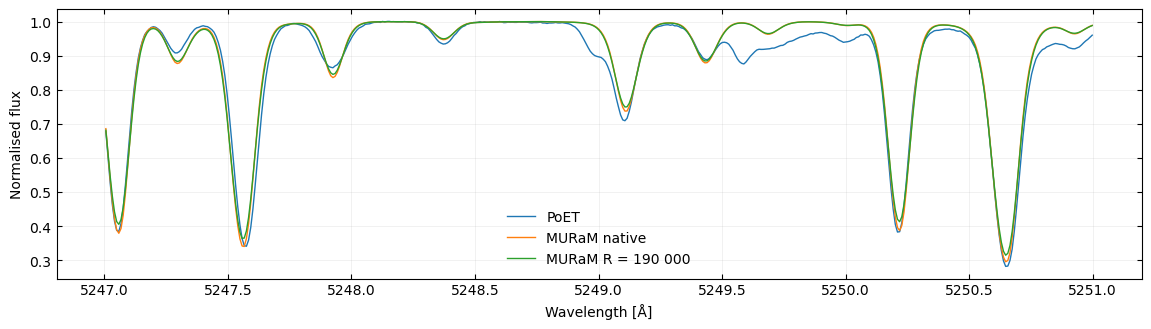

In [5]:
pad = (TEST_RANGE[0] - 20.0, TEST_RANGE[1] + 20.0)
w_d, f_d = lm.disc_integrate(lm.read_mu_spectra(MURAM, wave_range=pad), n_rings=60)
w_d = lm.vacuum_to_air(w_d)
w_d, f_d, _ = lm.flatten(w_d, f_d)
w_d, rv_m = lm.to_rest(w_d, f_d, esp_csv['wave'].values, esp_csv['cont'].values)

m = pd.read_csv(MURAM_DISC_FILE)
ok = np.isfinite(m['flux'].values)
w_m, f_m0 = m['wave'].values[ok], m['flux'].values[ok]
f_m = lm.degrade_resolution(w_m, f_m0, RESOLUTION)
z = (w_m > TEST_RANGE[0]) & (w_m < TEST_RANGE[1])
print('MURaM disc: RV %.0f m/s removed; built here - file in TEST_RANGE: rms %.4f, largest |difference| %.4f'
      % (rv_m, np.std(np.interp(w_m[z], w_d, f_d) - f_m0[z]), np.max(np.abs(np.interp(w_m[z], w_d, f_d) - f_m0[z]))))

zp = (w_p > TEST_RANGE[0]) & (w_p < TEST_RANGE[1])
rows = {}
for name, f in (('native', f_m0), ('R = 190 000', f_m)):
    wc, fpc, fmc, _, _ = lm.common_grid(w_p[zp], f_p[zp], w_m, f)
    a, b, _ = lm.pair_lines(lm.detect_lines(wc, fpc), lm.detect_lines(wc, fmc))
    rows['MURaM ' + name] = {'common lines with PoET': len(a), 'median depth MURaM - PoET': np.median(b['depth'] - a['depth'])}
display(pd.DataFrame(rows).T)
fig, ax = plt.subplots(figsize=(14, 3.5))
for (w, f), lab in (((w_p, f_p), 'PoET'), ((w_m, f_m0), 'MURaM native'), ((w_m, f_m), 'MURaM R = 190 000')):
    z = (w > 5247) & (w < 5251)
    ax.plot(w[z], f[z], lw=1, label=lab)
ax.set_xlabel('Wavelength [Å]'); ax.set_ylabel('Normalised flux'); ax.legend(frameon=False); lp._style(ax)
plt.show()

## 5. Telluric model

PoET / MURaM leaves the telluric lines (MURaM has none). `making_mask_flags.ipynb` (section 2) fits HITRAN H₂O and O₂
(`lm.hitran_tau_grid`, `lm.fit_tellurics_joint`) in the six bands at once: one column per molecule, one pressure and
temperature per molecule, one velocity, a resolution per band, on the pixels where MURaM > 0.95. The model is read
here. Only H₂O and O₂ are modelled: CO₂ and CH₄ stay below 0.03 % at R = 190 000, and the other absorbers of the
optical are broad bands removed by the flattening (`tellurics_fit.ipynb`, last section). **Test**: rms of PoET / MURaM
− model in every band.

,joint fit: rms absorbed,joint fit: rms all
O2 gamma,0.028,0.023
O2 B,0.014,0.014
O2 A,0.055,0.060
H2O 5900,0.010,0.010
H2O 6500,0.012,0.027
H2O 7250,0.016,0.014


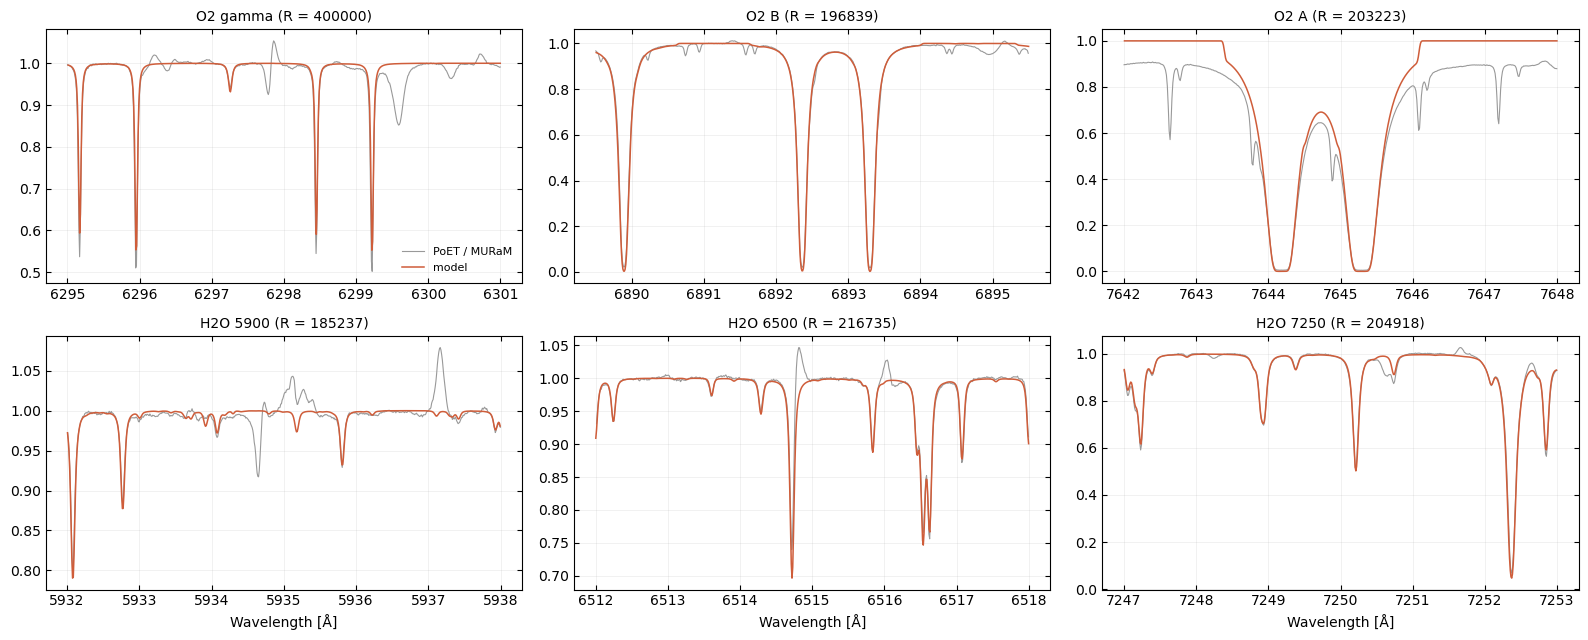

In [6]:
tell = lm.load_spectrum(TELL_FILE)[:2]
best = pd.read_csv(TELL_FITS).iloc[0]
wc, fpc, fmc, _, _ = lm.common_grid(w_p, f_p, w_m, f_m)
display(lm.fit_quality(wc, fpc, fmc, {'joint fit': tell}))
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5))
for ax, (band, (mol, region, _)) in zip(axes.flat, lm.tellurics.BANDS.items()):
    mid = 0.5 * (region[0] + region[1])
    q, r = np.abs(wc - mid) < 3, np.abs(tell[0] - mid) < 3
    ax.plot(wc[q], fpc[q] / fmc[q], color='0.6', lw=0.8, label='PoET / MURaM')
    ax.plot(tell[0][r], tell[1][r], color=lp.SERIES[1], lw=1.1, label='model')
    ax.set_title('%s (R = %.0f)' % (band, best['R ' + band]), fontsize=10); lp._style(ax)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.set_xlabel('Wavelength [Å]')
plt.tight_layout()
plt.show()

## 6. Lines

In PoET and MURaM, on the same pixels (`lm.common_grid`) over the whole range: every minimum of prominence ≥ 0.05
(`find_peaks` on −flux); its minimum from a gaussian fit of the core (flux < minimum + 0.2 × depth; the minimum pixel
if the fit fails, `center_ok` False); its window from the smoothed first and second derivatives (`edges='curvature'`:
outwards while the flux rises by more than 3σ, σ = the PoET error, its median for MURaM). The global shift (step 7)
and the MURaM noise are taken over the whole range. **Test**: window edges at the first local maximum against the
derivatives.

lines: PoET 5524, MURaM 4926; gaussian fit failed (minimum pixel): PoET 2, MURaM 2
PoET, TEST_RANGE: 795 lines, edges moved: left 295, right 319; window median 0.307 -> 0.363 Å


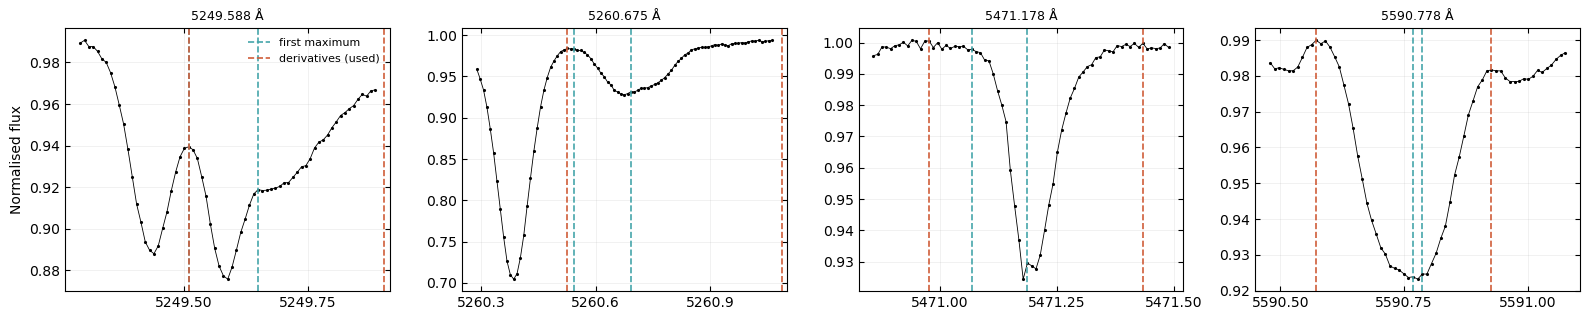

In [7]:
k = (w_p > FULL_RANGE[0]) & (w_p < FULL_RANGE[1])
wave, fo, fs, eo, _ = lm.common_grid(w_p[k], f_p[k], w_m, f_m, error_a=e_p[k])
EDGES = dict(edges='curvature', sg_window=TH['sg_window'], sg_order=TH['sg_order'], edge_sigma=TH['edge_sigma'])
lo = lm.detect_lines(wave, fo, TH['prominence'], 'gaussian', TH['core'], error=eo, **EDGES)
ls = lm.detect_lines(wave, fs, TH['prominence'], 'gaussian', TH['core'], error=np.median(eo), **EDGES)
print('lines: PoET %d, MURaM %d; gaussian fit failed (minimum pixel): PoET %d, MURaM %d'
      % (len(lo), len(ls), (~lo['center_ok']).sum(), (~ls['center_ok']).sum()))

r = (wave > TEST_RANGE[0]) & (wave < TEST_RANGE[1])
first = lm.detect_lines(wave[r], fo[r], TH['prominence'], 'pixel')
curv = lm.detect_lines(wave[r], fo[r], TH['prominence'], 'pixel', error=eo[r], **EDGES)
ed = first.merge(curv, on='wave_min_pixel', suffixes=('_first', '_curv'))
wf, wn = (ed['wave_right_max_' + x] - ed['wave_left_max_' + x] for x in ('first', 'curv'))
print('PoET, TEST_RANGE: %d lines, edges moved: left %d, right %d; window median %.3f -> %.3f Å'
      % (len(ed), (ed['i_left_first'] != ed['i_left_curv']).sum(), (ed['i_right_first'] != ed['i_right_curv']).sum(),
         wf.median(), wn.median()))
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
for ax, (_, row) in zip(axes, ed.loc[(wn / wf).sort_values().index[-4:]].iterrows()):
    c0, hw = row['wave_min_pixel'], 0.7 * (row['wave_right_max_curv'] - row['wave_left_max_curv'])
    q = np.abs(wave - c0) < max(hw, 0.3)
    ax.plot(wave[q], fo[q], 'k.-', ms=2.5, lw=0.6)
    for x, col, lab in (('first', lp.SERIES[2], 'first maximum'), ('curv', lp.SERIES[1], 'derivatives (used)')):
        ax.axvline(row['wave_left_max_' + x], color=col, ls='--', lw=1.2, label=lab)
        ax.axvline(row['wave_right_max_' + x], color=col, ls='--', lw=1.2)
    ax.set_title('%.3f Å' % c0, fontsize=9); ax.xaxis.set_major_locator(plt.MaxNLocator(3)); lp._style(ax)
axes[0].legend(frameon=False, fontsize=8); axes[0].set_ylabel('Normalised flux')
plt.tight_layout()
plt.show()

## 7. Pairs

`lm.pair_lines`: one to one, the closest first, within 4 km$\,$s$^{-1}$ once the global shift is removed (the median
Δv of the pairs within 2 km$\,$s$^{-1}$); `flag_dv`: |Δv| > 2 km$\,$s$^{-1}$. A pair is removed when the minimum of one
line is outside the window of the other. `lm.shared_window` (`'min'`): from the innermost to the innermost maximum of
the two lines, the window of the weights and of the VALD and telluric tests (each line's own window: `*_own`). **Test**: PoET − MURaM minima.

pairs within 4 km/s: 4071 (global shift MURaM - PoET 6.4 m/s); window rule: 11 removed
4060 common lines, flag_dv 139


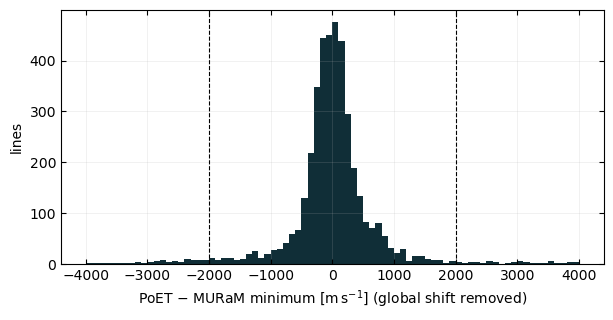

In [8]:
_, _, shift = lm.pair_lines(lo, ls, max_dv=TH['max_dv'])
co, cs, shift = lm.pair_lines(lo, ls, max_dv=TH['max_dv_pair'], shift=shift)
co, cs = lm.shared_window(co, cs, wave, wave, 'min')
tab = pd.concat([co.add_prefix('obs_'), cs.add_prefix('syn_')], axis=1)     # obs_: PoET, syn_: MURaM
tab['dv'] = tab.pop('obs_dv')
tab = tab.drop(columns=['syn_dv'])
tab['flag_dv'] = np.abs(tab['dv']) > TH['max_dv']
s_ = shift / C
out = (~(tab['obs_wave_min'] * (1 + s_)).between(tab['syn_wave_left_max_own'], tab['syn_wave_right_max_own'], inclusive='neither')
       | ~(tab['syn_wave_min'] * (1 - s_)).between(tab['obs_wave_left_max_own'], tab['obs_wave_right_max_own'], inclusive='neither')).values
print('pairs within %.0f km/s: %d (global shift MURaM - PoET %.1f m/s); window rule: %d removed'
      % (TH['max_dv_pair'] / 1e3, len(tab), shift, out.sum()))
keep = ~out
tab, co, cs = (x[keep].reset_index(drop=True) for x in (tab, co, cs))
print('%d common lines, flag_dv %d' % (len(tab), tab['flag_dv'].sum()))
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.hist(-tab['dv'], bins=np.linspace(-4000, 4000, 81), color=lp.SERIES[0])
for x in (-TH['max_dv'], TH['max_dv']):
    ax.axvline(x, color='k', ls='--', lw=0.8)
ax.set_xlabel(r'PoET − MURaM minimum [m$\,$s$^{-1}$] (global shift removed)'); ax.set_ylabel('lines'); lp._style(ax)
plt.show()

## 8. Tellurics

`lm.telluric_depth`: the largest depth of the model in the shared window widened by ± 1 km$\,$s$^{-1}$ (motion of the
tellurics relative to the Sun); `flag_telluric` above 0.1 %. **Test**: thresholds 0.1-5 % on every common line (no other
flag): lines flagged (also without widening and with ± 2 km$\,$s$^{-1}$), their share of the
PoET weight, and the RV of PoET and MURaM with the remaining lines (tellurics are in PoET only: PoET − MURaM). Telluric
depth of every line along the wavelength.

flag_telluric: 860 lines


,lines flagged,no widening,± 2 km/s,weight flagged [%],RV PoET [m/s],RV MURaM [m/s],PoET − MURaM [m/s]
no telluric flag,0,0,0,0.000,-39.517,-53.256,13.739
depth > 0.1 % (used),860,809,900,18.904,-39.240,-40.261,1.021
depth > 0.2 %,599,564,641,13.479,-39.990,-45.783,5.793
depth > 0.5 %,375,351,402,8.644,-43.818,-51.894,8.076
depth > 1.0 %,258,233,284,6.335,-42.961,-50.744,7.783
depth > 2.0 %,168,152,192,4.776,-42.233,-50.477,8.245
depth > 5.0 %,88,81,101,3.500,-42.304,-50.651,8.347


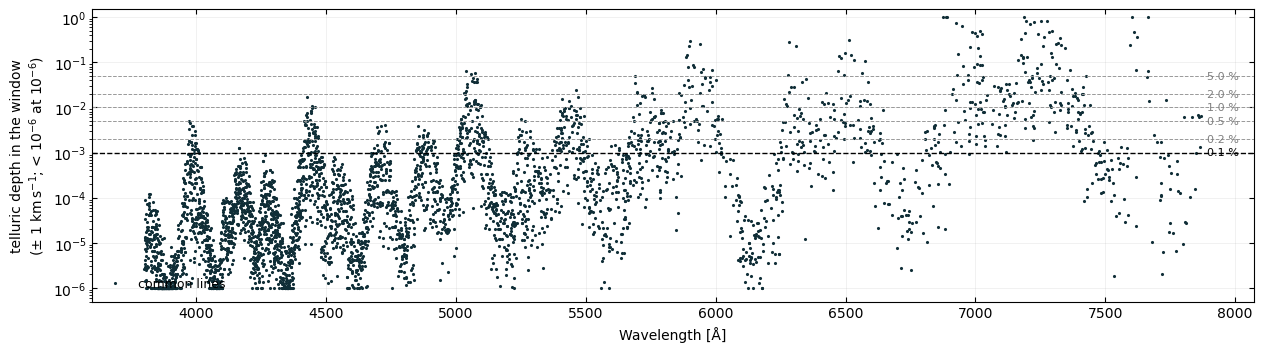

In [9]:
tab['tell_depth'] = lm.telluric_depth(tab['obs_wave_left_max'].values, tab['obs_wave_right_max'].values, *tell, TH['telluric_dv'])
tab['flag_telluric'] = tab['tell_depth'] > TH['telluric']
print('flag_telluric: %d lines' % tab['flag_telluric'].sum())

THRESHOLDS = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05)
td = {n: lm.telluric_depth(tab['obs_wave_left_max'].values, tab['obs_wave_right_max'].values, *tell, dv)
      for n, dv in (('used', TH['telluric_dv']), ('no widening', (0.0, 0.0)), ('± 2 km/s', (-2000.0, 2000.0)))}
w_full = lm.rv_weights(wave, fo, None, co)['weight'].values
mk = lambda keep_: pd.DataFrame({'wave': tab.loc[keep_, 'obs_wave_min'].values, 'weight': w_full[keep_] / w_full[keep_].sum()})
masks, rows = {'no telluric flag': mk(np.ones(len(tab), bool))}, {}
for t in THRESHOLDS:
    n = 'depth > %.1f %%%s' % (100 * t, ' (used)' if t == TH['telluric'] else '')
    bad = td['used'] > t
    masks[n] = mk(~bad)
    rows[n] = {'lines flagged': bad.sum(), 'no widening': (td['no widening'] > t).sum(), '± 2 km/s': (td['± 2 km/s'] > t).sum(),
               'weight flagged [%]': 100 * w_full[bad].sum() / w_full.sum()}
ct, _ = lm.compare_ccfs({'PoET': (w_p, f_p), 'MURaM': (w_m, f_m)}, masks)
res = pd.concat([pd.DataFrame({'lines flagged': 0, 'no widening': 0, '± 2 km/s': 0, 'weight flagged [%]': 0.0},
                              index=['no telluric flag']), pd.DataFrame(rows).T])
res = res.astype({'lines flagged': int, 'no widening': int, '± 2 km/s': int})
res['RV PoET [m/s]'] = ct.loc['PoET', 'rv']
res['RV MURaM [m/s]'] = ct.loc['MURaM', 'rv']
res['PoET − MURaM [m/s]'] = res['RV PoET [m/s]'] - res['RV MURaM [m/s]']
display(res)

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.semilogy(tab['obs_wave_min'], np.maximum(td['used'], 1e-6), '.', ms=2.5, color=lp.SERIES[0], label='common lines')
for t in THRESHOLDS:
    used = t == TH['telluric']
    ax.axhline(t, color='k' if used else '0.6', ls='--', lw=1.0 if used else 0.7)
    ax.text(tab['obs_wave_min'].max() + 20, t, '%.1f %%' % (100 * t), va='center', fontsize=8, color='k' if used else '0.5')
ax.set_ylim(5e-7, 1.5)
ax.set_xlabel('Wavelength [Å]'); ax.set_ylabel('telluric depth in the window\n(± 1 km$\\,$s$^{-1}$; < 10$^{-6}$ at 10$^{-6}$)')
ax.legend(frameon=False, fontsize=9, loc='lower left'); lp._style(ax)
plt.show()

## 9. Lines in every exposure

Each S1D is flattened with the continuum of the stack × its scale factor and kept in its own frame (the windows are
shifted by the RV of the stack). A line is found in an exposure when it has a minimum of prominence ≥ 0.025 (half the
mask threshold: one exposure is ~9 times noisier) inside the PoET window of the line (`lm.flags.presence_in_windows`).
**Test**: the flagged lines in the stack and in every exposure.

flag_not_in_all_s1d: 7 lines


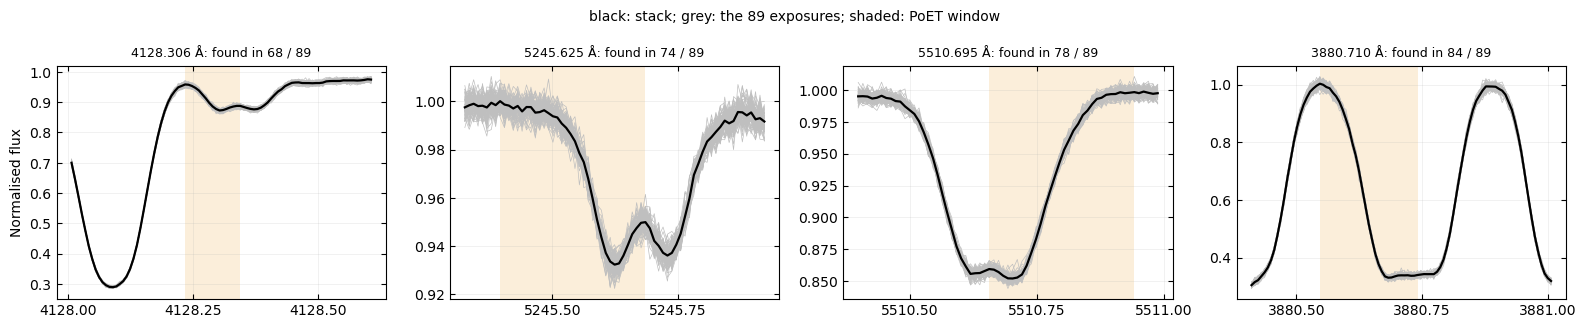

In [10]:
s1d = []
for path, scale in zip(S1D_FILES, s1d_info['scale']):
    w, fl, _, _ = lm.read_s1d(path)
    q = (w > FULL_RANGE[0] - 5) & (w < FULL_RANGE[1] + 5)
    s1d.append(lm.flatten(w[q], fl[q], continuum=np.interp(w[q], w_raw, cont_stack) / scale)[:2])
tab['n_s1d'] = lm.flags.presence_in_windows(s1d, tab['obs_wave_left_max_own'], tab['obs_wave_right_max_own'],
                                            TH['s1d_prominence'], shift=rv_stack)
tab['flag_not_in_all_s1d'] = tab['n_s1d'] < len(s1d)
print('flag_not_in_all_s1d: %d lines' % tab['flag_not_in_all_s1d'].sum())
ex = tab[tab['flag_not_in_all_s1d']].sort_values('n_s1d').head(4)
fig, axes = plt.subplots(1, max(len(ex), 1), figsize=(4 * max(len(ex), 1), 3.3), squeeze=False)
for ax, (_, row) in zip(axes[0], ex.iterrows()):
    c0 = row['obs_wave_min']
    for w, fl in s1d:
        q = np.abs(w - c0 * (1 + rv_stack / C)) < 0.3
        ax.plot(w[q] * (1 - rv_stack / C), fl[q], color='0.75', lw=0.5)
    q = np.abs(w_p - c0) < 0.3
    ax.plot(w_p[q], f_p[q], color='k', lw=1.6)
    ax.axvspan(row['obs_wave_left_max_own'], row['obs_wave_right_max_own'], color=lp.SERIES[3], alpha=0.2, lw=0)
    ax.set_title('%.3f Å: found in %d / %d' % (c0, row['n_s1d'], len(s1d)), fontsize=9)
    ax.xaxis.set_major_locator(plt.MaxNLocator(3)); lp._style(ax)
axes[0, 0].set_ylabel('Normalised flux')
fig.suptitle('black: stack; grey: the 89 exposures; shaded: PoET window', fontsize=10)
plt.tight_layout()
plt.show()

## 10. VALD matching

`lm.identify` on the PoET minimum, depth and shared window: the candidates are the VALD lines between the two maxima;
the identified one has the lowest score, the distance in resolution elements plus |ln(k × VALD depth / depth)| (VALD
depths are unbroadened; k = median depth / VALD depth of the closest candidates). `flag_no_vald`: no candidate.
`n_blend` (other candidates deeper than 0.5 × the line, more than 0.01 Å away) is kept as information. **Tests**: the
same identification from the MURaM minimum and depth (same window, so the same candidates); for PoET and MURaM: the
number of candidates (all, and deeper than 0.5 × the line), blends, the identified line against the closest candidate,
the identifications that change with the old score (`score='window'`), k, minimum − VALD wavelength (median, 16-84 %,
beyond one resolution element c / R); the same against the number of candidates; the PoET and MURaM identifications
against each other; the species; the deepest lines where PoET and MURaM identify different VALD lines.

flag_no_vald: 9; more than one candidate: 2921; blends: 1175
same candidates in PoET and MURaM: 4060 of 4060 lines; PoET and MURaM identify different VALD lines: 321 (c / R = 1578 m/s)


,PoET,MURaM
lines,4060.000,4060.000
no candidate,9.000,9.000
1 candidate,1130.000,1130.000
more than one candidate,2921.000,2921.000
more than one deeper than 0.5 x line,1284.000,1243.000
blends (n_blend > 0),1175.000,1125.000
identified is not the closest,456.000,512.000
changed with the old score,798.000,651.000
k (depth / VALD depth),0.850,0.838
minimum - VALD: median [m/s],178.337,173.602


,lines,median |PoET - VALD| [m/s],median |MURaM - VALD| [m/s],PoET and MURaM differ,changed with the old score,blends
candidates in the window,,,,,,
0,9,NaN,NaN,0,0,0
1,1130,212.331,251.567,0,0,0
2,896,249.274,302.000,64,155,195
3,691,265.270,311.439,65,172,227
4,434,291.937,385.482,47,122,185
>= 5,900,379.439,458.355,145,349,568


species,Fe 1,Ni 1,Cr 1,Ti 1,CH 1,Co 1,Ti 2,Mn 1,Fe 2,Si 1,V 1,CN 1
species,,,,,,,,,,,,
PoET,1978,312,297,259,242,113,110,92,92,89,88,81
MURaM,2023,311,307,249,236,118,109,98,91,91,90,67


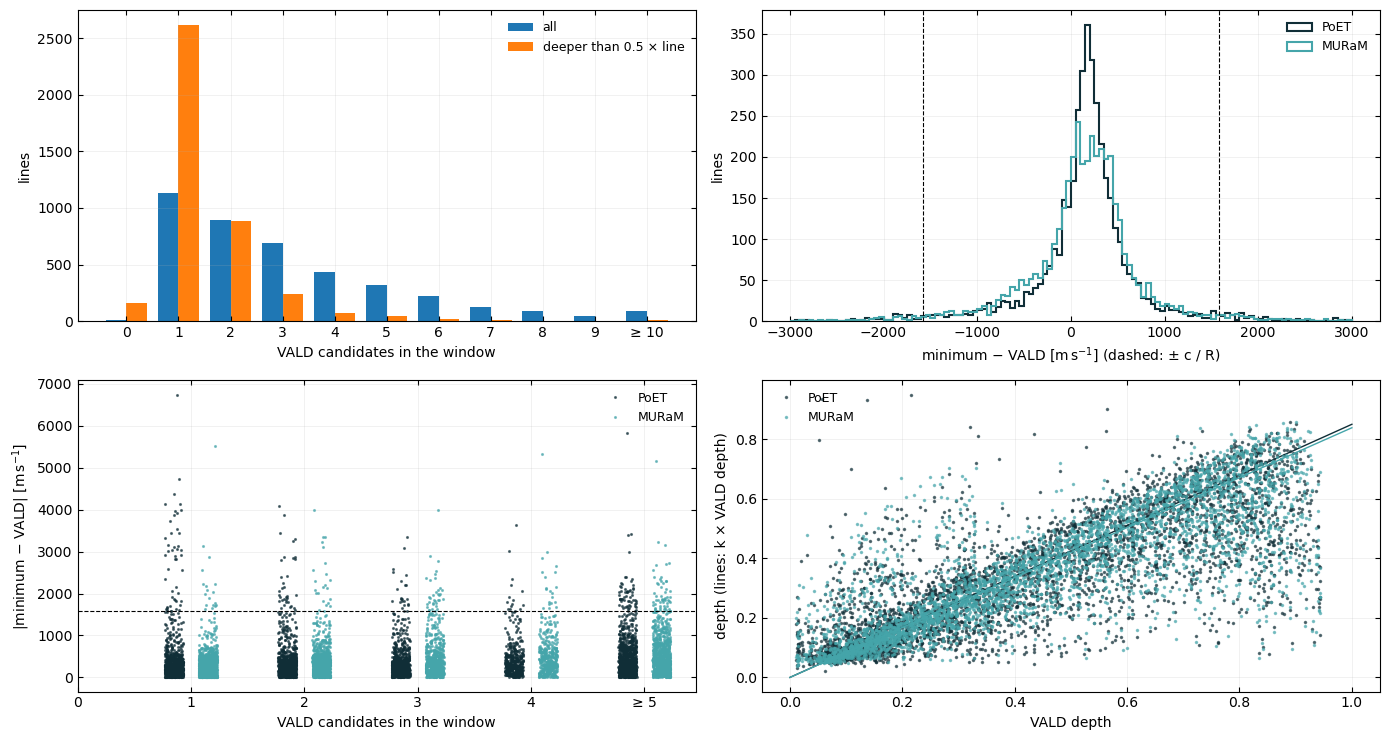

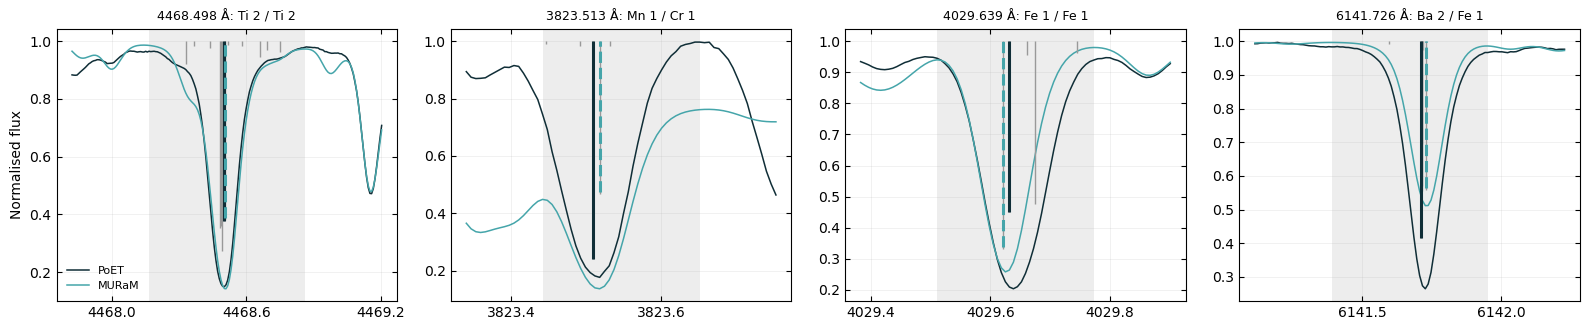

In [11]:
vald = lm.load_vald(VALD_FILE)
ID_KW = dict(blend_depth=TH['blend_depth'], blend_min_sep=TH['blend_min_sep'])
NAMES = {'obs': 'PoET', 'syn': 'MURaM'}
lines_ = {p: pd.DataFrame({c: tab[p + '_' + c] for c in ('wave_min', 'depth', 'wave_left_max', 'wave_right_max')}) for p in NAMES}
ids = {p: lm.identify(lines_[p], vald, resolution=RESOLUTION, **ID_KW) for p in NAMES}
old = {p: lm.identify(lines_[p], vald, score='window', **ID_KW) for p in NAMES}
for c in ('vald_index', 'vald_wave', 'vald_depth', 'species', 'n_candidates', 'n_blend'):
    tab[c] = ids['obs'][c].values
tab['flag_no_vald'] = tab['vald_index'] < 0
print('flag_no_vald: %d; more than one candidate: %d; blends: %d'
      % (tab['flag_no_vald'].sum(), (tab['n_candidates'] > 1).sum(), (tab['n_blend'] > 0).sum()))

# PoET and MURaM
vw, vd = vald['wave'].values, vald['depth_vald'].values
dvs, rows = {}, {}
for p, n in NAMES.items():
    d = ids[p]
    ok = d['vald_index'] >= 0
    dvs[p] = C * (d['wave_min'] - d['vald_wave']) / d['vald_wave']
    closest = np.array([c[np.argmin(np.abs(vw[c] - w))] if len(c) else -1 for c, w in zip(d['candidates'], d['wave_min'])])
    rows[n] = {'lines': len(d), 'no candidate': (~ok).sum(), '1 candidate': (d['n_candidates'] == 1).sum(),
               'more than one candidate': (d['n_candidates'] > 1).sum(),
               'more than one deeper than 0.5 x line': (d['n_candidates_deep'] > 1).sum(),
               'blends (n_blend > 0)': (d['n_blend'] > 0).sum(),
               'identified is not the closest': (ok & (closest != d['vald_index'])).sum(),
               'changed with the old score': (old[p]['vald_index'].values != d['vald_index'].values).sum(),
               'k (depth / VALD depth)': d.attrs['vald_depth_scale'],
               'minimum - VALD: median [m/s]': np.nanmedian(dvs[p]),
               'minimum - VALD: 16 % [m/s]': np.nanpercentile(dvs[p], 16),
               'minimum - VALD: 84 % [m/s]': np.nanpercentile(dvs[p], 84),
               '|minimum - VALD| > c / R': (np.abs(dvs[p]) > C / RESOLUTION).sum()}
diff = ids['obs']['vald_index'].values != ids['syn']['vald_index'].values
same_c = np.array([list(a) == list(b) for a, b in zip(ids['obs']['candidates'], ids['syn']['candidates'])])
print('same candidates in PoET and MURaM: %d of %d lines; PoET and MURaM identify different VALD lines: %d (c / R = %.0f m/s)'
      % (same_c.sum(), len(tab), diff.sum(), C / RESOLUTION))
display(pd.DataFrame(rows))

# against the number of candidates
nc = ids['obs']['n_candidates'].clip(upper=5)
chg = pd.Series(old['obs']['vald_index'].values != ids['obs']['vald_index'].values)
by = pd.DataFrame({'lines': nc.value_counts().sort_index(),
                   'median |PoET - VALD| [m/s]': dvs['obs'].abs().groupby(nc).median(),
                   'median |MURaM - VALD| [m/s]': dvs['syn'].abs().groupby(nc).median(),
                   'PoET and MURaM differ': pd.Series(diff).groupby(nc).sum(),
                   'changed with the old score': chg.groupby(nc).sum(),
                   'blends': (ids['obs']['n_blend'] > 0).groupby(nc).sum()})
by.index = ['%d' % i if i < 5 else '>= 5' for i in by.index]
display(by.rename_axis('candidates in the window'))

# species
sp = pd.DataFrame({n: ids[p].loc[ids[p]['vald_index'] >= 0, 'species'].value_counts() for p, n in NAMES.items()})
display(sp.fillna(0).astype(int).sort_values('PoET', ascending=False).head(12).T.rename_axis('species'))

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
x = np.arange(0, 11)
for off, (col, lab) in ((-0.2, ('n_candidates', 'all')), (0.2, ('n_candidates_deep', 'deeper than 0.5 × line'))):
    cnt = ids['obs'][col].clip(upper=10).value_counts().reindex(x, fill_value=0)
    axes[0, 0].bar(x + off, cnt.values, width=0.4, label=lab)
axes[0, 0].set_xticks(x, [str(i) for i in x[:-1]] + ['≥ 10'])
axes[0, 0].set_xlabel('VALD candidates in the window'); axes[0, 0].set_ylabel('lines')
bins = np.linspace(-3000, 3000, 121)
for p, col in (('obs', lp.SERIES[0]), ('syn', lp.SERIES[2])):
    axes[0, 1].hist(dvs[p].dropna(), bins=bins, histtype='step', lw=1.5, color=col, label=NAMES[p])
for sg in (-1, 1):
    axes[0, 1].axvline(sg * C / RESOLUTION, color='k', ls='--', lw=0.8)
axes[0, 1].set_xlabel(r'minimum − VALD [m$\,$s$^{-1}$] (dashed: ± c / R)'); axes[0, 1].set_ylabel('lines')
rng = np.random.default_rng(1)
for p, col, o in (('obs', lp.SERIES[0], -0.15), ('syn', lp.SERIES[2], 0.15)):
    axes[1, 0].plot(nc + o + rng.uniform(-0.08, 0.08, len(nc)), dvs[p].abs(), '.', ms=2.5, alpha=0.6, color=col, label=NAMES[p])
axes[1, 0].axhline(C / RESOLUTION, color='k', ls='--', lw=0.8)
axes[1, 0].set_xticks(range(6), ['0', '1', '2', '3', '4', '≥ 5'])
axes[1, 0].set_xlabel('VALD candidates in the window'); axes[1, 0].set_ylabel(r'|minimum − VALD| [m$\,$s$^{-1}$]')
for p, col in (('obs', lp.SERIES[0]), ('syn', lp.SERIES[2])):
    axes[1, 1].plot(ids[p]['vald_depth'], ids[p]['depth'], '.', ms=3, alpha=0.6, color=col, label=NAMES[p])
    axes[1, 1].plot([0, 1], [0, ids[p].attrs['vald_depth_scale']], color=col, lw=1)
axes[1, 1].set_xlabel('VALD depth'); axes[1, 1].set_ylabel('depth (lines: k × VALD depth)')
for ax in axes.flat:
    ax.legend(frameon=False, fontsize=9); lp._style(ax)
plt.tight_layout()
plt.show()

# deepest lines identified differently by PoET and MURaM: candidates (grey, height k × VALD depth), identified (PoET
# solid, MURaM dashed), shared window shaded
ex = tab.index[diff][np.argsort(-tab.loc[diff, 'obs_depth'].values)][:4]
if len(ex):
    fig, axes = plt.subplots(1, len(ex), figsize=(4 * len(ex), 3.4), squeeze=False)
    kk = {p: ids[p].attrs['vald_depth_scale'] for p in NAMES}
    for ax, i in zip(axes[0], ex):
        wl, wr = tab.loc[i, 'obs_wave_left_max'], tab.loc[i, 'obs_wave_right_max']
        q = (wave > wl - 0.5 * (wr - wl)) & (wave < wr + 0.5 * (wr - wl))
        ax.axvspan(wl, wr, color='0.93', lw=0, zorder=0)
        ax.plot(wave[q], fo[q], color=lp.SERIES[0], lw=1.1, label='PoET')
        ax.plot(wave[q], fs[q], color=lp.SERIES[2], lw=1.1, label='MURaM')
        for j in ids['obs'].loc[i, 'candidates']:
            ax.vlines(vw[j], 1 - kk['obs'] * vd[j], 1, color='0.6', lw=1)
        for p, ls in (('obs', '-'), ('syn', '--')):
            j = ids[p].loc[i, 'vald_index']
            if j >= 0:
                ax.vlines(vw[j], 1 - kk[p] * vd[j], 1, color=lp.SERIES[0] if p == 'obs' else lp.SERIES[2], lw=2.2, ls=ls)
        ax.set_title('%.3f Å: %s / %s' % (tab.loc[i, 'obs_wave_min'], ids['obs'].loc[i, 'species'], ids['syn'].loc[i, 'species']),
                     fontsize=9)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3)); lp._style(ax)
    axes[0, 0].legend(frameon=False, fontsize=8); axes[0, 0].set_ylabel('Normalised flux')
    plt.tight_layout()
    plt.show()

## 11. Weights

`lm.rv_weights` (Bouchy et al. 2001, eq. 8): W = Σ λ² (∂A₀/∂λ)² / (A₀ + σ_D²) over the shared window, A₀ = the flattened
flux of each spectrum, σ_D = 0: the weight depends on the line only, not on the S/N. With the measured error of the
stack instead, the photon-noise RV error of each line (`obs_sigma_rv_stack`). **Test**: PoET against MURaM weights of the same lines (against ESPRESSO: step 12).

In [12]:
tab['obs_weight'] = lm.rv_weights(wave, fo, None, co)['weight'].values
tab['syn_weight'] = lm.rv_weights(wave, fs, None, cs)['weight'].values
tab['obs_sigma_rv_stack'] = lm.rv_weights(wave, fo, eo, co)['sigma_rv'].values
pos = (tab['obs_weight'] > 0) & (tab['syn_weight'] > 0)
lw = np.log10(tab.loc[pos, ['obs_weight', 'syn_weight']] / tab.loc[pos, ['obs_weight', 'syn_weight']].sum())
d = lw['obs_weight'] - lw['syn_weight']
print('PoET vs MURaM weights (%d lines): r of the log weights %.3f; log10(PoET / MURaM) median %.3f, 16-84 %%: %.3f to %.3f'
      % (pos.sum(), np.corrcoef(lw['obs_weight'], lw['syn_weight'])[0, 1], d.median(), *np.percentile(d, [16, 84])))

PoET vs MURaM weights (4060 lines): r of the log weights 0.890; log10(PoET / MURaM) median -0.000, 16-84 %: -0.195 to 0.156


## 12. ESPRESSO matching

`lm.match_reference`: the ESPRESSO lines are matched one to one, closest first, within 0.11 Å of the VALD wavelength of
each line (the mean of the two minima when it has none). `flag_esp_far`: matched, but the PoET or the MURaM minimum is
more than 0.05 Å from the ESPRESSO line. Lines without an ESPRESSO line are kept. **Tests**: minimum − ESPRESSO, and
the weights against ESPRESSO (contrast²) on the matched lines, with σ_D = 0 (used) and without the denominator (σ = 1).

ESPRESSO lines matched: 2858 of 3297 (95.6 % of their weight); flag_esp_far: 11


,σ_D = 0 (used),σ = 1
r of the log weights,,
PoET vs ESPRESSO,0.978,0.966
MURaM vs ESPRESSO,0.861,0.836


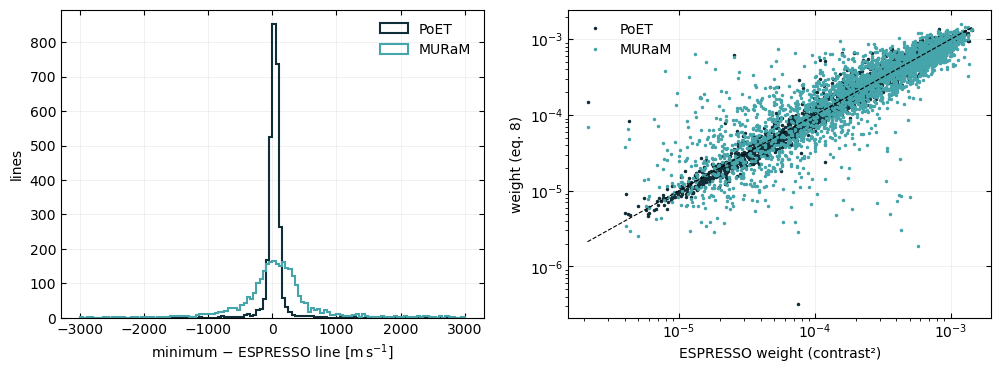

In [13]:
ref = lm.load_reference_mask(ESPRESSO_FILE, weight='contrast2')
key = np.where(tab['flag_no_vald'], 0.5 * (tab['obs_wave_min'] + tab['syn_wave_min']), tab['vald_wave'])
mt = lm.match_reference(key, ref['wave'].values, TH['esp_tol'])
li, ri = mt['line_index'].values, mt['ref_index'].values
tab['in_espresso'], tab['esp_wave'], tab['esp_weight'] = False, np.nan, np.nan
tab.loc[li, 'in_espresso'] = True
tab.loc[li, 'esp_wave'] = ref['wave'].values[ri]
tab.loc[li, 'esp_weight'] = ref['weight'].values[ri]
far = ((np.abs(tab['obs_wave_min'] - tab['esp_wave']) > TH['esp_max_dwave'])
       | (np.abs(tab['syn_wave_min'] - tab['esp_wave']) > TH['esp_max_dwave']))
tab['flag_esp_far'] = tab['in_espresso'] & far
inr = ref['wave'].between(*FULL_RANGE)
print('ESPRESSO lines matched: %d of %d (%.1f %% of their weight); flag_esp_far: %d'
      % (len(mt), inr.sum(), 100 * ref['weight'].values[ri].sum() / ref.loc[inr, 'weight'].sum(), tab['flag_esp_far'].sum()))

e = tab[tab['in_espresso']].copy()
for p, f in (('obs', fo), ('syn', fs)):
    e[p + '_weight_s1'] = lm.rv_weights(wave, f, 1.0, co.loc[e.index] if p == 'obs' else cs.loc[e.index])['weight'].values
logr = lambda x, y: np.corrcoef(np.log10(x), np.log10(y))[0, 1]
display(pd.DataFrame({'σ_D = 0 (used)': [logr(e['esp_weight'], e['obs_weight']), logr(e['esp_weight'], e['syn_weight'])],
                      'σ = 1': [logr(e['esp_weight'], e['obs_weight_s1']), logr(e['esp_weight'], e['syn_weight_s1'])]},
                     index=['PoET vs ESPRESSO', 'MURaM vs ESPRESSO']).rename_axis('r of the log weights'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for p, col, lab in (('obs', lp.SERIES[0], 'PoET'), ('syn', lp.SERIES[2], 'MURaM')):
    axes[0].hist(C * (e[p + '_wave_min'] - e['esp_wave']) / e['esp_wave'], bins=np.linspace(-3000, 3000, 121),
                 histtype='step', lw=1.5, color=col, label=lab)
nw = lambda x: x / x.sum()
axes[1].loglog(nw(e['esp_weight']), nw(e['obs_weight']), '.', ms=3, color=lp.SERIES[0], label='PoET')
axes[1].loglog(nw(e['esp_weight']), nw(e['syn_weight']), '.', ms=3, color=lp.SERIES[2], label='MURaM')
lim = [nw(e['esp_weight']).min(), nw(e['esp_weight']).max()]
axes[1].plot(lim, lim, 'k--', lw=0.8)
axes[0].set_xlabel(r'minimum − ESPRESSO line [m$\,$s$^{-1}$]'); axes[0].set_ylabel('lines')
axes[1].set_xlabel('ESPRESSO weight (contrast²)'); axes[1].set_ylabel('weight (eq. 8)')
for ax in axes:
    ax.legend(frameon=False); lp._style(ax)
plt.show()

## 13. Mask

The mask is the lines with no flag, at the PoET minimum with the PoET weight. **Tests**: the flags and their overlaps,
the lines along the wavelength, and the CCF of PoET and MURaM with the mask, with every flag put back, and with the
ESPRESSO mask (RV, FWHM, BIS). **Test** of the telluric threshold on the RV time series: the 89
exposures (step 9, each in its own frame) with the mask built with thresholds 0.1-5 % and without telluric flag (the
other flags kept): RV, FWHM and BIS scatter, the scatter of the RV difference to the mask used, and the correlation of
that difference with the airmass and the BERV (the tellurics move relative to the Sun during the night).

,lines,weight share [%],only this flag
flag_dv,139.000,1.887,95.000
flag_telluric,860.000,18.904,824.000
flag_not_in_all_s1d,7.000,0.031,6.000
flag_no_vald,9.000,0.052,8.000
flag_esp_far,11.000,0.189,3.000
no flag,3079.000,79.781,NaN


mask: 3079 lines; photon-noise RV error on the stack 0.018 m/s


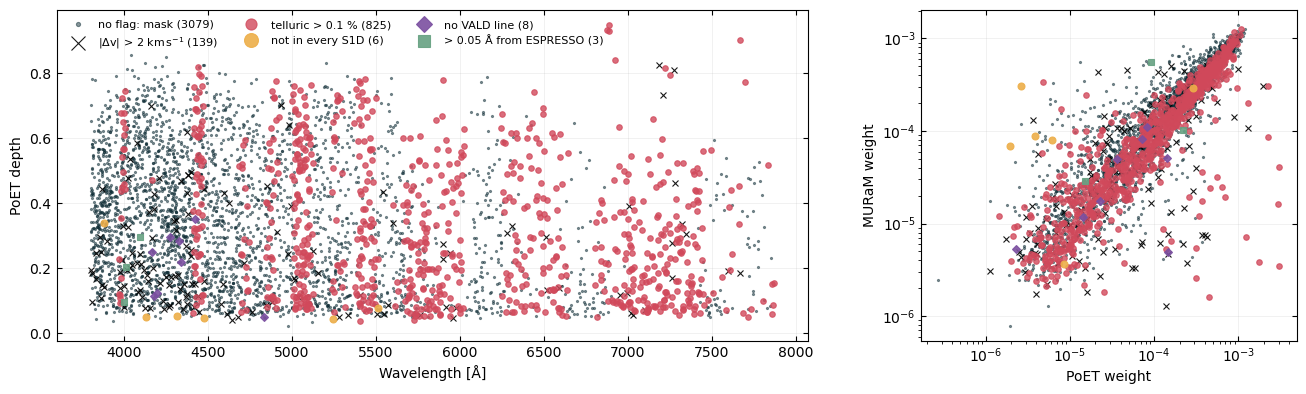

rv     fwhm     bis  lines used
spectrum mask                                                            
PoET     mask                        -39.346 6896.065 -45.876        3079
         + flag_dv lines             -38.743 6900.659 -44.635        3174
         + flag_telluric lines       -36.202 6891.191 -48.865        3903
         + flag_not_in_all_s1d lines -39.147 6898.053 -45.312        3085
         + flag_no_vald lines        -39.389 6895.793 -45.986        3087
         + flag_esp_far lines        -39.536 6895.422 -46.319        3082
         ESPRESSO                    -14.672 6826.987 -65.932        3297
MURaM    mask                        -38.821 7113.142 -58.522        3079
         + flag_dv lines             -37.457 7126.020 -55.176        3174
         + flag_telluric lines       -44.161 7149.071 -66.093        3903
         + flag_not_in_all_s1d lines -38.724 7114.830 -58.027        3085
         + flag_no_vald lines        -38.925 7112.955 -58.688        3087
         + flag_esp_far lines        -38.516 7112.754 -58.369        3082
         ESPRESSO                    -29.903 7049.317 -83.708        3297

In [14]:
noflag = lm.flags.select(tab, FLAGS)
norm = lambda w, x: pd.DataFrame({'wave': w, 'weight': x / x.sum()}).sort_values('wave', ignore_index=True)
mask = norm(tab.loc[noflag, 'obs_wave_min'].values, tab.loc[noflag, 'obs_weight'].values)
display(lm.flags.summary(tab, FLAGS))
print('mask: %d lines; photon-noise RV error on the stack %.3f m/s' % (len(mask), lm.photon_rv_error(tab.loc[noflag, 'obs_sigma_rv_stack'])))

STYLES = {'no flag': dict(color=lp.SERIES[0], marker='.', ms=3, alpha=0.5, label='no flag: mask'),
          'flag_dv': dict(color='k', marker='x', ms=5, alpha=0.9, label=r'|Δv| > 2 km$\,$s$^{-1}$'),
          'flag_telluric': dict(color=lp.SERIES[6], marker='o', ms=4, alpha=0.8, label='telluric > %.1f %%' % (100 * TH['telluric'])),
          'flag_not_in_all_s1d': dict(color=lp.SERIES[3], marker='o', ms=5, alpha=0.9, label='not in every S1D'),
          'flag_no_vald': dict(color=lp.SERIES[4], marker='D', ms=4, alpha=0.9, label='no VALD line'),
          'flag_esp_far': dict(color=lp.SERIES[5], marker='s', ms=4, alpha=0.9, label='> 0.05 Å from ESPRESSO')}
cat = lm.flags.first_flag(tab, FLAGS)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), gridspec_kw={'width_ratios': (2, 1)})
lp.flag_scatter(axes[0], tab['obs_wave_min'], tab['obs_depth'], cat, STYLES)
axes[0].set_xlabel('Wavelength [Å]'); axes[0].set_ylabel('PoET depth')
axes[0].legend(frameon=False, fontsize=8, markerscale=2, ncol=3, loc='upper left')
lp.flag_scatter(axes[1], nw(tab['obs_weight']), nw(tab['syn_weight']), cat, STYLES, label=False)
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlabel('PoET weight'); axes[1].set_ylabel('MURaM weight')
for ax in axes:
    lp._style(ax)
plt.show()

masks = {'mask': mask}
for f in FLAGS:
    q = lm.flags.select(tab, [g for g in FLAGS if g != f])
    if q.sum() > noflag.sum():
        masks['+ %s lines' % f] = norm(tab.loc[q, 'obs_wave_min'].values, tab.loc[q, 'obs_weight'].values)
masks['ESPRESSO'] = norm(ref.loc[inr, 'wave'].values, ref.loc[inr, 'weight'].values)
table, _ = lm.compare_ccfs({'PoET': (w_p, f_p), 'MURaM': (w_m, f_m)}, masks)
display(table[['rv', 'fwhm', 'bis', 'lines used']])

89 exposures over 1.7 h; airmass 1.38-1.46; BERV -486 to -310 m/s


,lines,photon RV error per exposure [m/s],RV rms [m/s],RV peak-to-peak [m/s],FWHM rms [m/s],BIS rms [m/s],rms of RV - RV(used) [m/s],"r(RV - RV(used), airmass)","r(RV - RV(used), BERV)",slope with airmass [m/s per airmass]
no telluric flag,3903,0.152,1.772,13.074,1.244,1.323,1.571,-0.837,0.997,-54.891
0.1 % (used),3079,0.168,1.374,11.371,1.626,0.708,0.000,NaN,NaN,NaN
0.2 %,3337,0.162,1.368,11.244,1.370,0.664,0.049,0.072,-0.122,0.147
0.5 %,3557,0.157,1.359,11.260,1.461,0.652,0.071,-0.155,0.065,-0.462
1.0 %,3673,0.155,1.365,11.237,1.435,0.646,0.078,-0.115,0.046,-0.372
2.0 %,3761,0.154,1.365,11.254,1.320,0.626,0.084,-0.127,0.040,-0.448
5.0 %,3836,0.153,1.366,11.299,1.289,0.620,0.089,-0.186,0.081,-0.691


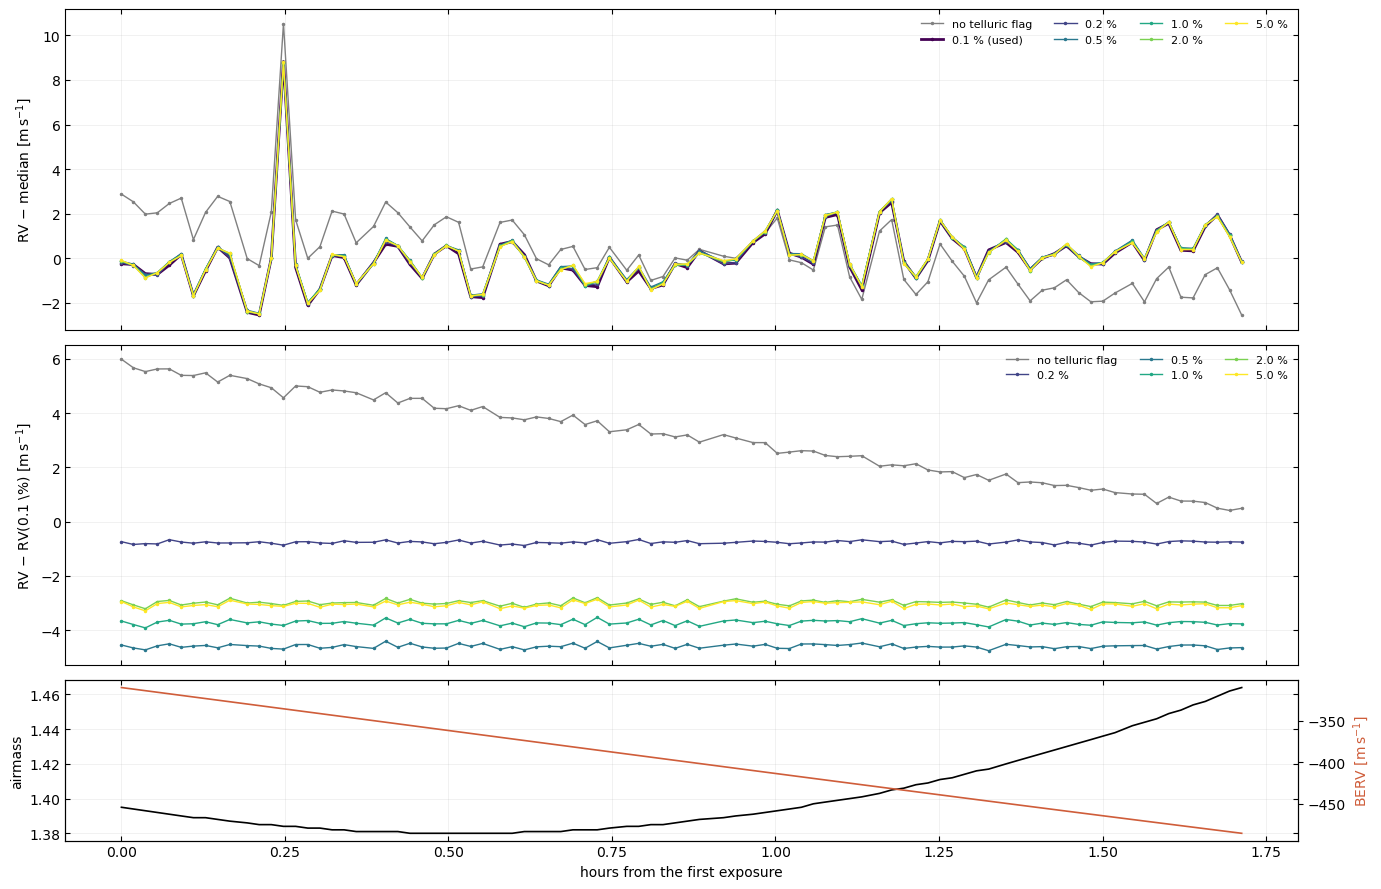

In [15]:
from astropy.io import fits
hdr = [fits.getheader(p, 0) for p in S1D_FILES]
airmass = np.array([0.5 * (h['HIERARCH ESO TEL5 AIRM START'] + h['HIERARCH ESO TEL5 AIRM END']) for h in hdr])
berv = s1d_info['berv'].values
hours = 24 * (s1d_info['bjd'].values - s1d_info['bjd'].min())
base = lm.flags.select(tab, [f for f in FLAGS if f != 'flag_telluric'])
used = '%.1f %%' % (100 * TH['telluric'])
ts_masks = {'no telluric flag': norm(tab.loc[base, 'obs_wave_min'].values, tab.loc[base, 'obs_weight'].values)}
for t in THRESHOLDS:
    q = base & (tab['tell_depth'] <= t)
    ts_masks['%.1f %%' % (100 * t)] = norm(tab.loc[q, 'obs_wave_min'].values, tab.loc[q, 'obs_weight'].values)
ts, _ = lm.ccf_timeseries(s1d, ts_masks)
rows = {}
for n, m in ts_masks.items():
    rv = ts[n + '_rv'].values
    dd = rv - ts[used + '_rv'].values
    q = base & ((tab['tell_depth'] <= float(n.split()[0]) / 100) if n[0].isdigit() else True)
    rows[n + (' (used)' if n == used else '')] = {
        'lines': len(m), 'photon RV error per exposure [m/s]': lm.photon_rv_error(tab.loc[q, 'obs_sigma_rv_stack']) * np.sqrt(len(s1d)),
        'RV rms [m/s]': np.std(rv), 'RV peak-to-peak [m/s]': np.ptp(rv),
        'FWHM rms [m/s]': np.std(ts[n + '_fwhm']), 'BIS rms [m/s]': np.std(ts[n + '_bis']),
        'rms of RV - RV(used) [m/s]': np.std(dd),
        'r(RV - RV(used), airmass)': np.corrcoef(dd, airmass)[0, 1] if n != used else np.nan,
        'r(RV - RV(used), BERV)': np.corrcoef(dd, berv)[0, 1] if n != used else np.nan,
        'slope with airmass [m/s per airmass]': np.polyfit(airmass, dd, 1)[0] if n != used else np.nan}
print('%d exposures over %.1f h; airmass %.2f-%.2f; BERV %.0f to %.0f m/s'
      % (len(s1d), hours.max(), airmass.min(), airmass.max(), berv.min(), berv.max()))
res_ts = pd.DataFrame(rows).T
res_ts['lines'] = res_ts['lines'].astype(int)
display(res_ts)

cmap = plt.get_cmap('viridis')
colors = {n: ('k' if n == 'no telluric flag' else cmap(k / (len(THRESHOLDS) - 1))) for k, n in enumerate(list(ts_masks)[1:])}
colors['no telluric flag'] = '0.5'
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': (2, 2, 1)})
for n in ts_masks:
    rv = ts[n + '_rv'].values
    lw = 2.0 if n == used else 1.0
    axes[0].plot(hours, rv - np.median(rv), '.-', ms=3, lw=lw, color=colors[n], label=n + (' (used)' if n == used else ''))
    if n != used:
        axes[1].plot(hours, rv - ts[used + '_rv'].values, '.-', ms=3, lw=1, color=colors[n], label=n)
axes[0].set_ylabel(r'RV − median [m$\,$s$^{-1}$]')
axes[1].set_ylabel(r'RV − RV(%s) [m$\,$s$^{-1}$]' % used.replace('%', r'\%'))
axes[2].plot(hours, airmass, color='k', lw=1.2)
axes[2].set_ylabel('airmass')
ax2 = axes[2].twinx()
ax2.plot(hours, berv, color=lp.SERIES[1], lw=1.2)
ax2.set_ylabel(r'BERV [m$\,$s$^{-1}$]', color=lp.SERIES[1])
axes[2].set_xlabel('hours from the first exposure')
axes[0].legend(frameon=False, fontsize=8, ncol=4)
axes[1].legend(frameon=False, fontsize=8, ncol=3)
for ax in axes:
    lp._style(ax)
plt.tight_layout()
plt.show()

In [16]:
if OUT is not None:
    os.makedirs(OUT, exist_ok=True)
    tab.to_csv(os.path.join(OUT, 'lines_flags_tutorial.csv'), index=False)      # every line with its flags
    lm.write_mask(mask, os.path.join(OUT, 'mask_tutorial.mas'))                  # for SunSim

## 14. `extract_mask`: the general case

`lm.extract_mask` does steps 6, 7, 8, 10 and 11 for one or more spectra (no `flag_dv`, presence in every exposure or ESPRESSO flag); every threshold is a flag column, and `res.mask(exclude=...)` makes masks with other choices without extracting again. **Test**: against the mask of step 13 (lines without
`telluric`): lines and weights matched one to one (`lm.compare_masks`, 2 km$\,$s$^{-1}$), and the CCFs of PoET and MURaM.

`lm.ExtractConfig` holds every parameter of `extract_mask` (saved with the mask by `save`):

| parameter | default | meaning |
|---|---|---|
| **detection** | | |
| `prominence` | 0.05 | minimum prominence of a line (flux, continuum = 1): `find_peaks` on −flux |
| `center` | `'gaussian'` | minimum of a line: fit of the core with a `'gaussian'` or a `'parabola'`, or the lowest `'pixel'` |
| `core` | 0.2 | pixels of the core fit: flux < minimum + `core` × depth |
| `edges` | `'first'` | window of a line: up to the `'first'` local maximum on each side, or `'curvature'` (derivatives of the smoothed flux, needs the errors) |
| `edge_sigma` | 3 | noise threshold of the `'curvature'` edges |
| **lines in every spectrum** | | |
| `max_dv` | 2000 m$\,$s$^{-1}$ | largest distance between paired minima, once the global shift is removed |
| `shift` | `None` | global shift of each other spectrum relative to the primary one; `None`: median of the pairs |
| `window` | `'min'` | pixels of the weight: `'min'` the window shared by all the spectra, `'max'` their union, `'own'` each its own |
| `position` | `'primary'` | mask wavelength: minimum of the `'primary'` spectrum, or `'mean'` of the minima (shift removed) |
| **weights** (Bouchy et al. 2001 eq. 8, A0 = flattened flux) | | |
| `detector_noise` | 0 | σ_D, in units of the continuum |
| **flags** | | |
| `min_depth` | 0 | `shallow`: depth below this in one of the spectra |
| `vald_score` | `'resolution'` | identification: the line-list line between the two maxima minimising \|Δλ\| / (λ / `resolution`) + `log_depth_weight` × \|ln(k × depth_VALD / depth)\|; `'window'`: the old score `distance_weight` × \|Δλ\| / window + `depth_weight` × \|Δdepth\| / depth |
| `log_depth_weight`, `vald_depth_scale` | 1, `None` | weight of the log depth ratio; k (`None`: median depth / depth_VALD of the closest candidate, VALD depths are unbroadened) |
| `distance_weight`, `depth_weight` | 0.5, 0.5 | `'window'` score only |
| `blend_depth`, `blend_min_sep` | 0.5, 0.01 Å | `blend`: another line-list line deeper than `blend_depth` × the line depth in the window, more than `blend_min_sep` from the identified one |
| `require_vald` | `False` | `True`: lines without a line-list line (`no_vald`) are left out of the default masks |
| `telluric_threshold` | 0.01 (here 0.001, as step 8) | `telluric`: telluric depth above this in the window (needs `telluric=`) |
| `telluric_dv` | (−1000, 1000) m$\,$s$^{-1}$ | range of telluric velocities relative to the lines |
| `resolution` | `None` | resolving power of the spectra; distance unit of the VALD identification (needed with `vald=`) |

In [17]:
cfg = lm.ExtractConfig(prominence=TH['prominence'], window='min', edges='curvature', max_dv=TH['max_dv'], min_depth=0.1,
                       resolution=RESOLUTION, telluric_threshold=TH['telluric'], telluric_dv=TH['telluric_dv'])
r = (wave > FULL_RANGE[0]) & (wave < FULL_RANGE[1])
pm = lm.extract_mask({'PoET': (wave[r], fo[r], eo[r]), 'MURaM': (wave[r], fs[r], np.full(r.sum(), np.median(eo)))}, cfg,
                     vald=vald, telluric=tell)                 # MURaM error: only for its window edges, as in step 6
display(pm.flag_summary())
pd.Series({'all lines': len(pm.mask(exclude=())),
           'no telluric, depth > 0.1': len(pm.mask(exclude=('telluric', 'shallow'))),
           '+ no blend': len(pm.mask(exclude=('telluric', 'shallow', 'blend')))}).to_frame('lines')

,lines,weight share [%],only this flag
telluric,825.000,18.561,542.000
shallow,608.000,1.585,336.000
no_vald,8.000,0.052,6.000
blend,1119.000,31.704,882.000
no flag,1766.000,53.190,NaN


,lines
all lines,3925
"no telluric, depth > 0.1",2654
+ no blend,1772


In [18]:
pm_mask = pm.mask(exclude=('telluric',))
cm = lm.compare_masks(pm_mask, mask, max_dv=TH['max_dv'], names=('extract_mask', 'step 13'))
display(pd.Series(cm['counts']).to_frame('extract_mask vs step 13'))
table14, _ = lm.compare_ccfs({'PoET': (w_p, f_p), 'MURaM': (w_m, f_m)}, {'extract_mask': pm_mask, 'step 13': mask})
display(table14[['rv', 'fwhm', 'bis', 'lines used']])

,extract_mask vs step 13
extract_mask lines,3100.000
step 13 lines,3079.000
matched lines,3079.000
extract_mask weight matched [%],99.816
step 13 weight matched [%],100.000
median |dv| [m/s],0.000
90% |dv| [m/s],0.000
weight r,1.000
log weight r,1.000


rv     fwhm     bis  lines used
spectrum mask                                             
PoET     extract_mask -39.583 6897.545 -46.115        3100
         step 13      -39.346 6896.065 -45.876        3079
MURaM    extract_mask -38.913 7114.433 -58.435        3100
         step 13      -38.821 7113.142 -58.522        3079